In [ ]:

import pandas as pd
import numpy as np
from google.colab import files
from IPython.display import display

# Cargar el archivo de datos
uploaded = files.upload()

nombre_archivo = next(iter(uploaded))

# Leer el archivo CSV
df = pd.read_csv(nombre_archivo, encoding="utf-8-sig")

print("Archivo cargado correctamente.")
print(f"Número de registros: {df.shape[0]:,}")
print(f"Número de variables: {df.shape[1]}")
display(df.head())


Saving Sin_Duplicados.xlsx - default_1.csv to Sin_Duplicados.xlsx - default_1.csv
Archivo cargado correctamente.
Número de registros: 33,842
Número de variables: 15


,No. de Radicado,Tipo comunicación,Clase,Tipo documento,Canal de recepción,Nombre del Peticionario / Remitente,Distribución,Dependencia asignada,Departamento,Municipio,No. Radicado de salida,Fecha radicación,Identificacion,Fecha vencimiento,Fecha Radicado salida
0,2025-313-000001-2,Comunicación Oficial Externa Recibida,OTRO,Oficio,Correo Electrónico,PRESIDENCIA DE LA REPÚBLICA,Electrónica,DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIED...,Bogota D.C.,Bogotá D.C.,2025-420-000713-1,2025-01-02 08:26:31,1111,2025-02-14 23:59:00,24/01/2025 11:13:47 a. m.
1,2025-313-000002-2,Comunicación Oficial Externa Recibida,OTRO,Oficio,Correo Electrónico,NaN,Electrónica,GRUPO DE TALENTO HUMANO,Sin Información Territorial,Sin Información Territorial,2025-311-000115-1,2025-01-02 08:37:39,1111,2025-02-14 23:59:00,8/01/2025 11:30:04 a. m.
2,2025-313-000003-2,Comunicación Oficial Externa Recibida,PQRSD,Solicitud de Información y/o Copia de documentos,Correo Electrónico,NaN,Electrónica,GRUPO DE CADENAS DE PRODUCTOS AGRÍCOLAS TRANSI...,Sin Información Territorial,Sin Información Territorial,2025-521-000903-1,2025-01-02 08:37:45,1111,2025-01-17 23:59:00,30/01/2025 9:22:12 a. m.
3,2025-313-000004-2,Comunicación Oficial Externa Recibida,OTRO,Otros,Correo Electrónico,NaN,Electrónica,"DIRECCIÓN DE CADENAS PECUARIAS, PESQUERAS Y AC...",Sin Información Territorial,Sin Información Territorial,2025-540-000056-1,2025-01-02 08:37:52,1111,2025-01-02 13:04:46,3/01/2025 11:55:49 a. m.
4,2025-313-000005-2,Comunicación Oficial Externa Recibida,OTRO,Oficio,Correo Electrónico,NaN,Electrónica,GRUPO DE CADENAS DE PRODUCTOS AGRÍCOLAS PERMAN...,Sin Información Territorial,Sin Información Territorial,2025-522-000932-1,2025-01-02 08:37:58,1111,2025-02-14 23:59:00,30/01/2025 3:18:04 p. m.


In [ ]:

# Estructura de las variables
df.info()

# Tipos de datos
print("\nTipos de datos:")
display(df.dtypes.rename("tipo_dato").to_frame())

# Valores faltantes
faltantes = pd.DataFrame({
    "valores_faltantes": df.isna().sum(),
    "porcentaje_faltante": (df.isna().mean() * 100).round(2)
})

faltantes = faltantes.sort_values(
    "porcentaje_faltante", ascending=False
)

print("\nValores faltantes por variable:")
display(faltantes)

# Registros duplicados exactos
print(
    "\nRegistros duplicados exactos:",
    df.duplicated().sum()
)

# Dimensiones de la base
print("\nDimensiones:", df.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33842 entries, 0 to 33841
Data columns (total 15 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   No. de Radicado                      33842 non-null  object
 1   Tipo comunicación                    33842 non-null  object
 2   Clase                                33842 non-null  object
 3   Tipo documento                       33842 non-null  object
 4   Canal de recepción                   33842 non-null  object
 5   Nombre del Peticionario / Remitente  30844 non-null  object
 6   Distribución                         32376 non-null  object
 7   Dependencia asignada                 33842 non-null  object
 8   Departamento                         33842 non-null  object
 9   Municipio                            33842 non-null  object
 10  No. Radicado de salida               17305 non-null  object
 11  Fecha radicación                     3384

,tipo_dato
No. de Radicado,object
Tipo comunicación,object
Clase,object
Tipo documento,object
Canal de recepción,object
Nombre del Peticionario / Remitente,object
Distribución,object
Dependencia asignada,object
Departamento,object
Municipio,object



Valores faltantes por variable:


,valores_faltantes,porcentaje_faltante
No. Radicado de salida,16537,48.87
Nombre del Peticionario / Remitente,2998,8.86
Fecha vencimiento,2678,7.91
Distribución,1466,4.33
Tipo comunicación,0,0.00
Clase,0,0.00
No. de Radicado,0,0.00
Tipo documento,0,0.00
Canal de recepción,0,0.00
Departamento,0,0.00



Registros duplicados exactos: 0

Dimensiones: (33842, 15)


In [ ]:

columnas_fecha = [
    "Fecha radicación",
    "Fecha vencimiento",
    "Fecha Radicado salida"
]

for columna in columnas_fecha:
    print(f"\n--- {columna} ---")
    print("Ejemplos de valores:")
    display(df[columna].dropna().astype(str).head(10))

    fechas_convertidas = pd.to_datetime(
        df[columna],
        errors="coerce",
        dayfirst=True
    )

    invalidas = df[columna].notna() & fechas_convertidas.isna()

    print("Valores no vacíos que no se pudieron interpretar:",
          int(invalidas.sum()))



--- Fecha radicación ---
Ejemplos de valores:


,Fecha radicación
0,2025-01-02 08:26:31
1,2025-01-02 08:37:39
2,2025-01-02 08:37:45
3,2025-01-02 08:37:52
4,2025-01-02 08:37:58
5,2025-01-02 08:58:40
6,2025-01-02 09:09:29
7,2025-01-02 09:22:09
8,2025-01-02 09:37:14
9,2025-01-02 10:08:10


Valores no vacíos que no se pudieron interpretar: 20354

--- Fecha vencimiento ---
Ejemplos de valores:


,Fecha vencimiento
0,2025-02-14 23:59:00
1,2025-02-14 23:59:00
2,2025-01-17 23:59:00
3,2025-01-02 13:04:46
4,2025-02-14 23:59:00
5,2025-02-14 23:59:00
6,2025-01-09 11:49:14
7,2025-02-14 23:59:00
8,2025-01-14 11:16:25
9,2025-02-14 23:59:00


Valores no vacíos que no se pudieron interpretar: 0

--- Fecha Radicado salida ---
Ejemplos de valores:


/tmp/ipykernel_479/664142525.py:12: UserWarning: Parsing dates in %Y-%m-%d %H:%M:%S format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  fechas_convertidas = pd.to_datetime(


,Fecha Radicado salida
0,24/01/2025 11:13:47 a. m.
1,8/01/2025 11:30:04 a. m.
2,30/01/2025 9:22:12 a. m.
3,3/01/2025 11:55:49 a. m.
4,30/01/2025 3:18:04 p. m.
5,?
6,?
7,20/02/2025 10:12:23 a. m.
8,?
9,?


Valores no vacíos que no se pudieron interpretar: 28000


In [ ]:

# Crear una copia de trabajo para el ETL
df_etl = df.copy()

# 1. Convertir fecha de radicación
df_etl["Fecha radicación"] = pd.to_datetime(
    df_etl["Fecha radicación"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# 2. Convertir fecha de vencimiento
df_etl["Fecha vencimiento"] = pd.to_datetime(
    df_etl["Fecha vencimiento"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# 3. Normalizar fecha de radicado de salida
salida = (
    df_etl["Fecha Radicado salida"]
    .astype("string")
    .str.strip()
    .str.replace("\u00a0", " ", regex=False)
)

salida = salida.str.replace(
    r"\s+a\.\s*m\.$", " AM", regex=True
).str.replace(
    r"\s+p\.\s*m\.$", " PM", regex=True
)

# El signo ? se convierte en dato faltante
salida = salida.mask(salida == "?")

df_etl["Fecha Radicado salida"] = pd.to_datetime(
    salida,
    format="%d/%m/%Y %I:%M:%S %p",
    errors="coerce"
)

# 4. Verificar las conversiones
for columna in [
    "Fecha radicación",
    "Fecha vencimiento",
    "Fecha Radicado salida"
]:
    print(f"\n{columna}")
    print("Tipo de dato:", df_etl[columna].dtype)
    print("Valores faltantes:", df_etl[columna].isna().sum())
    print("Fechas válidas:", df_etl[columna].notna().sum())

display(df_etl[
    ["Fecha radicación", "Fecha vencimiento",
     "Fecha Radicado salida"]
].head(10))



Fecha radicación
Tipo de dato: datetime64[ns]
Valores faltantes: 0
Fechas válidas: 33842

Fecha vencimiento
Tipo de dato: datetime64[ns]
Valores faltantes: 2678
Fechas válidas: 31164

Fecha Radicado salida
Tipo de dato: datetime64[ns]
Valores faltantes: 16537
Fechas válidas: 17305


,Fecha radicación,Fecha vencimiento,Fecha Radicado salida
0,2025-01-02 08:26:31,2025-02-14 23:59:00,2025-01-24 11:13:47
1,2025-01-02 08:37:39,2025-02-14 23:59:00,2025-01-08 11:30:04
2,2025-01-02 08:37:45,2025-01-17 23:59:00,2025-01-30 09:22:12
3,2025-01-02 08:37:52,2025-01-02 13:04:46,2025-01-03 11:55:49
4,2025-01-02 08:37:58,2025-02-14 23:59:00,2025-01-30 15:18:04
5,2025-01-02 08:58:40,2025-02-14 23:59:00,NaT
6,2025-01-02 09:09:29,2025-01-09 11:49:14,NaT
7,2025-01-02 09:22:09,2025-02-14 23:59:00,2025-02-20 10:12:23
8,2025-01-02 09:37:14,2025-01-14 11:16:25,NaT
9,2025-01-02 10:08:10,2025-02-14 23:59:00,NaT


In [ ]:

# Variables categóricas y de identificación almacenadas como texto
columnas_texto = df_etl.select_dtypes(
    include=["object", "string"]
).columns

# Revisar espacios al inicio y al final
print("Espacios al inicio o al final:")
for columna in columnas_texto:
    serie = df_etl[columna].dropna().astype(str)
    cantidad = (
        serie != serie.str.strip()
    ).sum()

    if cantidad > 0:
        print(f"{columna}: {cantidad}")

# Revisar categorías más frecuentes
columnas_categoricas = [
    "Tipo comunicación",
    "Clase",
    "Tipo documento",
    "Canal de recepción",
    "Distribución",
    "Dependencia asignada",
    "Departamento",
    "Municipio"
]

for columna in columnas_categoricas:
    print(f"\n--- {columna} ---")
    display(
        df_etl[columna]
        .value_counts(dropna=False)
        .head(15)
        .rename_axis("categoría")
        .reset_index(name="frecuencia")
    )


Espacios al inicio o al final:
Nombre del Peticionario / Remitente: 1557

--- Tipo comunicación ---


,categoría,frecuencia
0,Comunicación Oficial Externa Recibida,33842



--- Clase ---


,categoría,frecuencia
0,OTRO,26386
1,PQRSD,7456



--- Tipo documento ---


...

,categoría,frecuencia
0,DIRECCIÓN DE GESTIÓN DE BIENES PÚBLICOS RURALES,4161
1,GRUPO DE TRABAJO DE PREVENCIÓN DEL DAÑO ANTIJU...,3670
2,DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIED...,3639
3,GRUPO DE GESTIÓN INTEGRAL DE ENTIDADES LIQUIDADAS,3232
4,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA,2626
5,DESPACHO DEL MINISTRO,2033
6,DIRECCIÓN DE CAPACIDADES PRODUCTIVAS Y GENERAC...,1895
7,OFICINA ASESORA JURÍDICA,1535
8,DIRECCIÓN DE CADENAS AGRÍCOLAS Y FORESTALES,1188
9,"DIRECCIÓN DE CADENAS PECUARIAS, PESQUERAS Y AC...",1003



--- Departamento ---


,categoría,frecuencia
0,Bogota D.C.,15500
1,Sin Información Territorial,14296
2,Antioquia,355
3,Valle Del Cauca,336
4,Meta,235
5,Tolima,229
6,Boyacá,222
7,Santander,199
8,Nariño,194
9,Magdalena,171



--- Municipio ---


,categoría,frecuencia
0,Bogotá D.C.,15423
1,Sin Información Territorial,14646
2,Medellín,213
3,Cali,161
4,Ibagué,123
5,Villavicencio,123
6,San José Del Guaviare,117
7,Mocoa,100
8,Paz De Río,96
9,Santa Marta,94


In [ ]:

# Crear una copia antes de aplicar nuevas transformaciones
df_etl = df_etl.copy()

# Registrar el estado previo
filas_antes = len(df_etl)
columnas_texto = df_etl.select_dtypes(
    include=["object", "string"]
).columns.tolist()

# Contar espacios sobrantes antes de la limpieza
reporte_textos = []

for columna in columnas_texto:
    serie = df_etl[columna].astype("string")
    con_espacios = serie.notna() & serie.ne(serie.str.strip())

    reporte_textos.append({
        "variable": columna,
        "valores_con_espacios_sobrantes": int(con_espacios.sum())
    })

reporte_textos = pd.DataFrame(reporte_textos)

print("Espacios sobrantes identificados antes de limpiar:")
display(reporte_textos)

# Limpiar únicamente espacios al inicio y al final
for columna in columnas_texto:
    df_etl[columna] = df_etl[columna].map(
        lambda valor: valor.strip()
        if isinstance(valor, str) else valor
    )

# Verificar que no se hayan eliminado registros
print("Filas antes:", filas_antes)
print("Filas después:", len(df_etl))
print("Columnas:", df_etl.shape[1])
print("Duplicados exactos:", df_etl.duplicated().sum())


Espacios sobrantes identificados antes de limpiar:


,variable,valores_con_espacios_sobrantes
0,No. de Radicado,0
1,Tipo comunicación,0
2,Clase,0
3,Tipo documento,0
4,Canal de recepción,0
5,Nombre del Peticionario / Remitente,1557
6,Distribución,0
7,Dependencia asignada,0
8,Departamento,0
9,Municipio,0


Filas antes: 33842
Filas después: 33842
Columnas: 15
Duplicados exactos: 0


In [ ]:

# Verificar duplicados en el número de radicado
col_radicado = "No. de Radicado"

print(
    "Radicados vacíos:",
    df_etl[col_radicado].isna().sum()
)

print(
    "Registros con radicado repetido:",
    df_etl[col_radicado].duplicated(keep=False).sum()
)

# Revisar fechas de salida anteriores a la radicación
salida_anterior = (
    df_etl["Fecha Radicado salida"].notna()
    & df_etl["Fecha radicación"].notna()
    & (
        df_etl["Fecha Radicado salida"]
        < df_etl["Fecha radicación"]
    )
)

print(
    "\nRegistros cuya fecha de salida es anterior a la radicación:",
    int(salida_anterior.sum())
)

# Revisar vencimientos anteriores a la radicación
vencimiento_anterior = (
    df_etl["Fecha vencimiento"].notna()
    & df_etl["Fecha radicación"].notna()
    & (
        df_etl["Fecha vencimiento"]
        < df_etl["Fecha radicación"]
    )
)

print(
    "Registros cuyo vencimiento es anterior a la radicación:",
    int(vencimiento_anterior.sum())
)


Radicados vacíos: 0
Registros con radicado repetido: 0

Registros cuya fecha de salida es anterior a la radicación: 97
Registros cuyo vencimiento es anterior a la radicación: 0


In [ ]:

# Identificar registros con fecha de salida anterior a la radicación
casos_fecha_inconsistente = df_etl.loc[
    df_etl["Fecha Radicado salida"].notna()
    & df_etl["Fecha radicación"].notna()
    & (
        df_etl["Fecha Radicado salida"]
        < df_etl["Fecha radicación"]
    ),
    [
        "No. de Radicado",
        "Fecha radicación",
        "No. Radicado de salida",
        "Fecha Radicado salida",
        "Fecha vencimiento",
        "Dependencia asignada"
    ]
].copy()

print("Cantidad de casos:", len(casos_fecha_inconsistente))
display(casos_fecha_inconsistente.head(15))


Cantidad de casos: 97


,No. de Radicado,Fecha radicación,No. Radicado de salida,Fecha Radicado salida,Fecha vencimiento,Dependencia asignada
227,2025-313-000228-2,2025-01-08 11:49:48,2024-313-026352-1,2024-11-22 13:50:53,2025-02-19 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
242,2025-313-000243-2,2025-01-08 15:23:57,2025-313-000241-2,2025-01-08 14:59:56,2025-02-19 23:59:00,DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIED...
481,2025-313-000482-2,2025-01-13 15:09:12,2025-313-000481-2,2025-01-13 15:09:06,2025-02-24 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
667,2025-313-000668-2,2025-01-16 09:52:25,2025-313-000481-2,2025-01-13 15:09:06,2025-02-27 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
951,2025-313-000952-2,2025-01-22 10:48:31,2025-313-000363-2,2025-01-10 08:31:49,2025-03-05 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
956,2025-313-000957-2,2025-01-22 11:15:59,2025-313-000922-2,2025-01-21 16:17:27,2025-03-05 23:59:00,DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIED...
1667,2025-313-001668-2,2025-02-03 07:54:13,2025-420-001199-3,2025-01-31 15:15:30,2025-03-17 23:59:00,"DIRECCIÓN DE CADENAS PECUARIAS, PESQUERAS Y AC..."
2888,2025-313-002889-2,2025-02-19 07:25:12,2025-313-002392-2,2025-02-12 12:13:46,2025-04-03 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
3243,2025-313-003244-2,2025-02-24 09:37:33,2025-313-002915-2,2025-02-19 10:00:12,2025-04-08 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
3527,2025-313-003528-2,2025-02-26 15:02:03,2025-313-002987-2,2025-02-20 07:44:04,2025-04-10 23:59:00,DESPACHO DEL MINISTRO


In [ ]:

# Guardar la base auditada en formato CSV
nombre_salida = "base_datos_auditada_etl.csv"

df_etl.to_csv(
    nombre_salida,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo generado:", nombre_salida)
print("Dimensiones:", df_etl.shape)

# Descargar el archivo a tu computador
from google.colab import files
files.download(nombre_salida)


Archivo generado: base_datos_auditada_etl.csv
Dimensiones: (33842, 15)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

casos_fecha_inconsistente = df_etl.loc[
    df_etl["Fecha Radicado salida"].notna()
    & df_etl["Fecha radicación"].notna()
    & (
        df_etl["Fecha Radicado salida"]
        < df_etl["Fecha radicación"]
    ),
    [
        "No. de Radicado",
        "Fecha radicación",
        "No. Radicado de salida",
        "Fecha Radicado salida",
        "Fecha vencimiento",
        "Dependencia asignada"
    ]
].copy()

print("Cantidad de casos:", len(casos_fecha_inconsistente))

display(casos_fecha_inconsistente.head(15))


Cantidad de casos: 97


,No. de Radicado,Fecha radicación,No. Radicado de salida,Fecha Radicado salida,Fecha vencimiento,Dependencia asignada
227,2025-313-000228-2,2025-01-08 11:49:48,2024-313-026352-1,2024-11-22 13:50:53,2025-02-19 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
242,2025-313-000243-2,2025-01-08 15:23:57,2025-313-000241-2,2025-01-08 14:59:56,2025-02-19 23:59:00,DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIED...
481,2025-313-000482-2,2025-01-13 15:09:12,2025-313-000481-2,2025-01-13 15:09:06,2025-02-24 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
667,2025-313-000668-2,2025-01-16 09:52:25,2025-313-000481-2,2025-01-13 15:09:06,2025-02-27 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
951,2025-313-000952-2,2025-01-22 10:48:31,2025-313-000363-2,2025-01-10 08:31:49,2025-03-05 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
956,2025-313-000957-2,2025-01-22 11:15:59,2025-313-000922-2,2025-01-21 16:17:27,2025-03-05 23:59:00,DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIED...
1667,2025-313-001668-2,2025-02-03 07:54:13,2025-420-001199-3,2025-01-31 15:15:30,2025-03-17 23:59:00,"DIRECCIÓN DE CADENAS PECUARIAS, PESQUERAS Y AC..."
2888,2025-313-002889-2,2025-02-19 07:25:12,2025-313-002392-2,2025-02-12 12:13:46,2025-04-03 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
3243,2025-313-003244-2,2025-02-24 09:37:33,2025-313-002915-2,2025-02-19 10:00:12,2025-04-08 23:59:00,GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA
3527,2025-313-003528-2,2025-02-26 15:02:03,2025-313-002987-2,2025-02-20 07:44:04,2025-04-10 23:59:00,DESPACHO DEL MINISTRO


In [ ]:

# Registrar las inconsistencias temporales sin modificar los datos
df_etl["Alerta_fecha_salida"] = (
    df_etl["Fecha Radicado salida"].notna()
    & df_etl["Fecha radicación"].notna()
    & (
        df_etl["Fecha Radicado salida"]
        < df_etl["Fecha radicación"]
    )
)

# Resumen de la auditoría
resumen_alertas = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Fechas de salida anteriores a la radicación",
        "Fechas de salida iguales o posteriores a la radicación",
        "Registros sin fecha de salida"
    ],
    "Cantidad": [
        len(df_etl),
        int(df_etl["Alerta_fecha_salida"].sum()),
        int((
            df_etl["Fecha Radicado salida"].notna()
            & ~df_etl["Alerta_fecha_salida"]
        ).sum()),
        int(df_etl["Fecha Radicado salida"].isna().sum())
    ]
})

display(resumen_alertas)


,Indicador,Cantidad
0,Total de registros,33842
1,Fechas de salida anteriores a la radicación,97
2,Fechas de salida iguales o posteriores a la ra...,17208
3,Registros sin fecha de salida,16537


In [ ]:

# Tabla consolidada de calidad de los datos

auditoria_final = pd.DataFrame({
    "Indicador": [
        "Número de registros",
        "Número de variables originales",
        "Duplicados exactos",
        "Radicados vacíos",
        "Radicados repetidos",
        "Nombres con espacios sobrantes identificados",
        "Faltantes en nombre del peticionario",
        "Faltantes en distribución",
        "Faltantes en fecha de vencimiento",
        "Faltantes en número de radicado de salida",
        "Fechas de salida anteriores a la radicación"
    ],
    "Resultado": [
        len(df_etl),
        15,
        int(df_etl.drop(columns=["Alerta_fecha_salida"]).duplicated().sum()),
        int(df_etl["No. de Radicado"].isna().sum()),
        int(df_etl["No. de Radicado"].duplicated().sum()),
        1557,
        int(df_etl["Nombre del Peticionario / Remitente"].isna().sum()),
        int(df_etl["Distribución"].isna().sum()),
        int(df_etl["Fecha vencimiento"].isna().sum()),
        int(df_etl["No. Radicado de salida"].isna().sum()),
        int(df_etl["Alerta_fecha_salida"].sum())
    ]
})

display(auditoria_final)


,Indicador,Resultado
0,Número de registros,33842
1,Número de variables originales,15
2,Duplicados exactos,0
3,Radicados vacíos,0
4,Radicados repetidos,0
5,Nombres con espacios sobrantes identificados,1557
6,Faltantes en nombre del peticionario,2998
7,Faltantes en distribución,1466
8,Faltantes en fecha de vencimiento,2678
9,Faltantes en número de radicado de salida,16537


In [ ]:

# Exportar la base procesada
archivo_etl = "base_datos_auditada_etl.csv"

df_etl.to_csv(
    archivo_etl,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado:", archivo_etl)
print("Registros:", df_etl.shape[0])
print("Variables:", df_etl.shape[1])

from google.colab import files
files.download(archivo_etl)


Archivo exportado: base_datos_auditada_etl.csv
Registros: 33842
Variables: 16


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

registro_etl = pd.DataFrame([
    {
        "Etapa": "Carga",
        "Operacion": "Lectura del archivo CSV",
        "Resultado": "33.842 registros y 15 variables originales"
    },
    {
        "Etapa": "Auditoría",
        "Operacion": "Revisión de duplicados exactos",
        "Resultado": "No se encontraron duplicados exactos"
    },
    {
        "Etapa": "Auditoría",
        "Operacion": "Revisión de radicados",
        "Resultado": "Sin radicados vacíos ni repetidos"
    },
    {
        "Etapa": "Limpieza",
        "Operacion": "Eliminación de espacios al inicio y al final",
        "Resultado": "Se identificaron 1.557 nombres con espacios sobrantes"
    },
    {
        "Etapa": "Transformación",
        "Operacion": "Conversión de las tres columnas de fecha",
        "Resultado": "Fechas convertidas a datetime; se conservaron los faltantes"
    },
    {
        "Etapa": "Auditoría temporal",
        "Operacion": "Identificación de fechas de salida anteriores a la radicación",
        "Resultado": "97 registros marcados con una alerta, sin modificar las fechas"
    }
])

display(registro_etl)

registro_etl.to_csv(
    "registro_transformaciones_etl.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Registro ETL guardado correctamente.")


In [ ]:
import pandas as pd
import os

print(os.listdir("/content"))


['.config', 'base_datos_auditada_etl.csv', 'Sin_Duplicados.xlsx - default_1.csv', 'sample_data']


In [ ]:
import pandas as pd

base_verificacion = pd.read_csv(
    "/content/base_datos_auditada_etl.csv"
)

print("Número de registros:", base_verificacion.shape[0])
print("Número de columnas:", base_verificacion.shape[1])

print("\nColumnas de la base:")
print(base_verificacion.columns.tolist())

print("\nPrimeras cinco filas:")
display(base_verificacion.head())

Número de registros: 33842
Número de columnas: 16

Columnas de la base:
['No. de Radicado', 'Tipo comunicación', 'Clase', 'Tipo documento', 'Canal de recepción', 'Nombre del Peticionario / Remitente', 'Distribución', 'Dependencia asignada', 'Departamento', 'Municipio', 'No. Radicado de salida', 'Fecha radicación', 'Identificacion', 'Fecha vencimiento', 'Fecha Radicado salida', 'Alerta_fecha_salida']

Primeras cinco filas:


,No. de Radicado,Tipo comunicación,Clase,Tipo documento,Canal de recepción,Nombre del Peticionario / Remitente,Distribución,Dependencia asignada,Departamento,Municipio,No. Radicado de salida,Fecha radicación,Identificacion,Fecha vencimiento,Fecha Radicado salida,Alerta_fecha_salida
0,2025-313-000001-2,Comunicación Oficial Externa Recibida,OTRO,Oficio,Correo Electrónico,PRESIDENCIA DE LA REPÚBLICA,Electrónica,DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIED...,Bogota D.C.,Bogotá D.C.,2025-420-000713-1,2025-01-02 08:26:31,1111,2025-02-14 23:59:00,2025-01-24 11:13:47,False
1,2025-313-000002-2,Comunicación Oficial Externa Recibida,OTRO,Oficio,Correo Electrónico,NaN,Electrónica,GRUPO DE TALENTO HUMANO,Sin Información Territorial,Sin Información Territorial,2025-311-000115-1,2025-01-02 08:37:39,1111,2025-02-14 23:59:00,2025-01-08 11:30:04,False
2,2025-313-000003-2,Comunicación Oficial Externa Recibida,PQRSD,Solicitud de Información y/o Copia de documentos,Correo Electrónico,NaN,Electrónica,GRUPO DE CADENAS DE PRODUCTOS AGRÍCOLAS TRANSI...,Sin Información Territorial,Sin Información Territorial,2025-521-000903-1,2025-01-02 08:37:45,1111,2025-01-17 23:59:00,2025-01-30 09:22:12,False
3,2025-313-000004-2,Comunicación Oficial Externa Recibida,OTRO,Otros,Correo Electrónico,NaN,Electrónica,"DIRECCIÓN DE CADENAS PECUARIAS, PESQUERAS Y AC...",Sin Información Territorial,Sin Información Territorial,2025-540-000056-1,2025-01-02 08:37:52,1111,2025-01-02 13:04:46,2025-01-03 11:55:49,False
4,2025-313-000005-2,Comunicación Oficial Externa Recibida,OTRO,Oficio,Correo Electrónico,NaN,Electrónica,GRUPO DE CADENAS DE PRODUCTOS AGRÍCOLAS PERMAN...,Sin Información Territorial,Sin Información Territorial,2025-522-000932-1,2025-01-02 08:37:58,1111,2025-02-14 23:59:00,2025-01-30 15:18:04,False


In [ ]:
import pandas as pd

base_verificacion = pd.read_csv(
    "/content/base_datos_auditada_etl.csv"
)

print("DIMENSIONES DE LA BASE")
print("Registros:", len(base_verificacion))
print("Columnas:", len(base_verificacion.columns))

print("\nVALORES FALTANTES POR VARIABLE")
faltantes = base_verificacion.isna().sum()
display(faltantes[faltantes > 0].to_frame("Valores faltantes"))

print("\nREGISTROS DUPLICADOS")
print(
    "Duplicados exactos:",
    base_verificacion.duplicated(
        subset=base_verificacion.columns.drop("Alerta_fecha_salida")
    ).sum()
)

print("\nALERTAS DE FECHA")
print(
    base_verificacion["Alerta_fecha_salida"]
    .value_counts(dropna=False)
)

print("\nTIPOS DE DATOS")
display(
    base_verificacion.dtypes.to_frame("Tipo de dato")
)

DIMENSIONES DE LA BASE
Registros: 33842
Columnas: 16

VALORES FALTANTES POR VARIABLE


,Valores faltantes
Nombre del Peticionario / Remitente,2998
Distribución,1466
No. Radicado de salida,16537
Fecha vencimiento,2678
Fecha Radicado salida,16537



REGISTROS DUPLICADOS
Duplicados exactos: 0

ALERTAS DE FECHA
Alerta_fecha_salida
False    33745
True        97
Name: count, dtype: int64

TIPOS DE DATOS


,Tipo de dato
No. de Radicado,object
Tipo comunicación,object
Clase,object
Tipo documento,object
Canal de recepción,object
Nombre del Peticionario / Remitente,object
Distribución,object
Dependencia asignada,object
Departamento,object
Municipio,object


In [ ]:
import pandas as pd

base_verificacion = pd.read_csv(
    "/content/base_datos_auditada_etl.csv"
)

# Convertir las fechas al tipo datetime
columnas_fecha = [
    "Fecha radicación",
    "Fecha vencimiento",
    "Fecha Radicado salida"
]

for columna in columnas_fecha:
    base_verificacion[columna] = pd.to_datetime(
        base_verificacion[columna],
        errors="coerce"
    )

# Verificar los cambios
print("TIPOS DE DATOS DESPUÉS DE LA CONVERSIÓN")
display(base_verificacion.dtypes.to_frame("Tipo de dato"))

print("\nVALORES FALTANTES EN LAS FECHAS")
display(
    base_verificacion[columnas_fecha]
    .isna()
    .sum()
    .to_frame("Valores faltantes")
)

print("\nREGISTROS CON ALERTA DE FECHA")
print(
    base_verificacion["Alerta_fecha_salida"].value_counts()
)

TIPOS DE DATOS DESPUÉS DE LA CONVERSIÓN


,Tipo de dato
No. de Radicado,object
Tipo comunicación,object
Clase,object
Tipo documento,object
Canal de recepción,object
Nombre del Peticionario / Remitente,object
Distribución,object
Dependencia asignada,object
Departamento,object
Municipio,object



VALORES FALTANTES EN LAS FECHAS


,Valores faltantes
Fecha radicación,0
Fecha vencimiento,2678
Fecha Radicado salida,16537



REGISTROS CON ALERTA DE FECHA
Alerta_fecha_salida
False    33745
True        97
Name: count, dtype: int64


In [ ]:
# Guardar la base con las fechas normalizadas
base_verificacion.to_csv(
    "/content/base_datos_auditada_etl_final.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Base final guardada correctamente.")
print("Registros:", base_verificacion.shape[0])
print("Columnas:", base_verificacion.shape[1])

Base final guardada correctamente.
Registros: 33842
Columnas: 16


In [ ]:
import os

print(
    "Archivo encontrado:",
    os.path.exists("/content/base_datos_auditada_etl_final.csv")
)

Archivo encontrado: True


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Cargar la base final
df = pd.read_csv(
    "/content/base_datos_auditada_etl_final.csv",
    parse_dates=[
        "Fecha radicación",
        "Fecha vencimiento",
        "Fecha Radicado salida"
    ]
)

print("Dimensiones de la base:", df.shape)

# 1. Distribución por clase
print("\nRADICADOS POR CLASE")
tabla_clase = df["Clase"].value_counts(dropna=False).to_frame("Cantidad")
tabla_clase["Porcentaje"] = (
    tabla_clase["Cantidad"] / len(df) * 100
).round(2)
display(tabla_clase)

# 2. Distribución por canal
print("\nRADICADOS POR CANAL DE RECEPCIÓN")
tabla_canal = df["Canal de recepción"].value_counts(dropna=False).to_frame("Cantidad")
tabla_canal["Porcentaje"] = (
    tabla_canal["Cantidad"] / len(df) * 100
).round(2)
display(tabla_canal)

# 3. Distribución mensual
df["Mes_radicacion"] = df["Fecha radicación"].dt.to_period("M").astype(str)
tabla_mensual = df["Mes_radicacion"].value_counts().sort_index().to_frame("Cantidad")
display(tabla_mensual)

Dimensiones de la base: (33842, 16)

RADICADOS POR CLASE


,Cantidad,Porcentaje
Clase,,
OTRO,26386,77.97
PQRSD,7456,22.03



RADICADOS POR CANAL DE RECEPCIÓN


,Cantidad,Porcentaje
Canal de recepción,,
Correo Electrónico,27473,81.18
Ventanilla Sede Principal,5587,16.51
Página Web,780,2.30
App PQRSD,2,0.01


,Cantidad
Mes_radicacion,
2025-01,1637
2025-02,2134
2025-03,2707
2025-04,3129
2025-05,2958
2025-06,2480
2025-07,3397
2025-08,3091
2025-09,3465


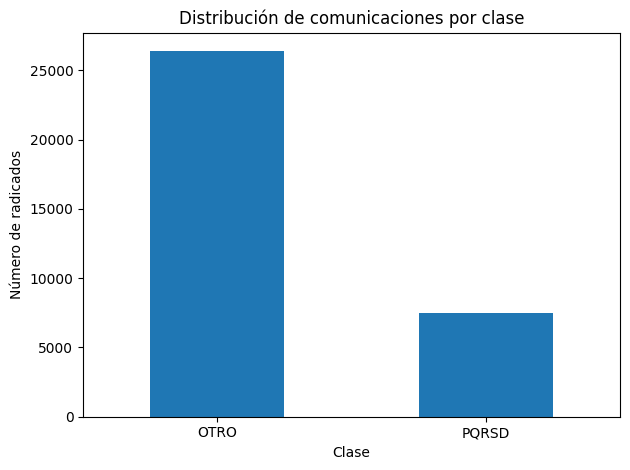

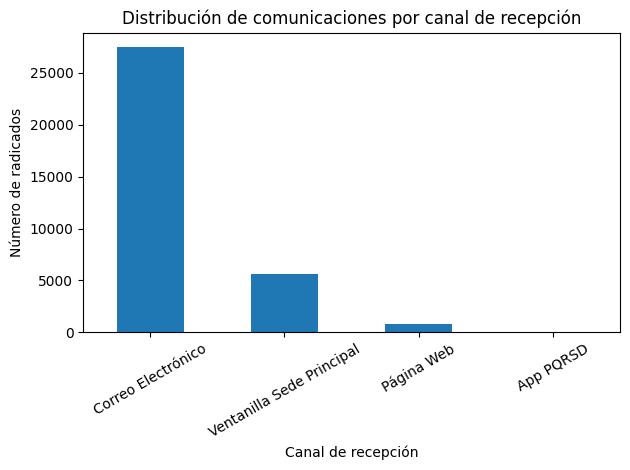

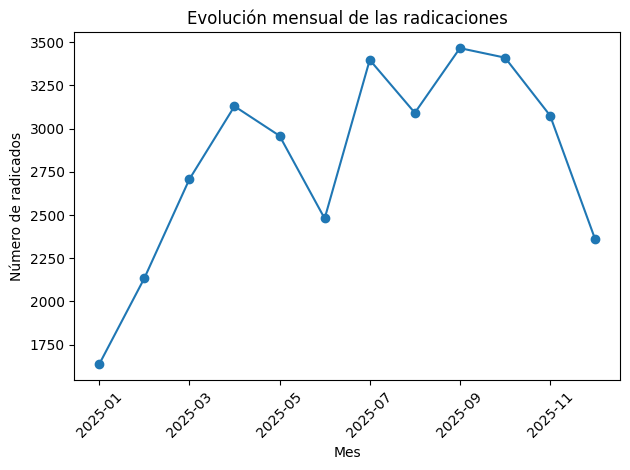

In [ ]:
# Gráfica 1: comunicaciones por clase
tabla_clase["Cantidad"].plot(kind="bar", rot=0)
plt.title("Distribución de comunicaciones por clase")
plt.xlabel("Clase")
plt.ylabel("Número de radicados")
plt.tight_layout()
plt.show()

# Gráfica 2: comunicaciones por canal
tabla_canal["Cantidad"].plot(kind="bar", rot=30)
plt.title("Distribución de comunicaciones por canal de recepción")
plt.xlabel("Canal de recepción")
plt.ylabel("Número de radicados")
plt.tight_layout()
plt.show()

# Gráfica 3: radicados por mes
tabla_mensual["Cantidad"].plot(kind="line", marker="o")
plt.title("Evolución mensual de las radicaciones")
plt.xlabel("Mes")
plt.ylabel("Número de radicados")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Diez dependencias con mayor cantidad de radicados
print("TOP 10 DEPENDENCIAS POR NÚMERO DE RADICADOS")

tabla_dependencias = (
    df["Dependencia asignada"]
    .value_counts(dropna=False)
    .head(10)
    .to_frame("Cantidad")
)

tabla_dependencias["Porcentaje del total"] = (
    tabla_dependencias["Cantidad"] / len(df) * 100
).round(2)

display(tabla_dependencias)


# 2. Presencia o ausencia de número de radicado de salida
print("\nREGISTROS SEGÚN DISPONIBILIDAD DEL RADICADO DE SALIDA")

df["Estado_registro_salida"] = df["No. Radicado de salida"].notna().map({
    True: "Con radicado de salida registrado",
    False: "Sin radicado de salida registrado"
})

tabla_salida = df["Estado_registro_salida"].value_counts().to_frame("Cantidad")

tabla_salida["Porcentaje"] = (
    tabla_salida["Cantidad"] / len(df) * 100
).round(2)

display(tabla_salida)

TOP 10 DEPENDENCIAS POR NÚMERO DE RADICADOS


,Cantidad,Porcentaje del total
Dependencia asignada,,
DIRECCIÓN DE GESTIÓN DE BIENES PÚBLICOS RURALES,4161,12.30
GRUPO DE TRABAJO DE PREVENCIÓN DEL DAÑO ANTIJURIDICO Y LITIGIO ESTRATEGICO,3670,10.84
DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIEDAD RURAL Y USO PRODUCTIVO DEL SUELO,3639,10.75
GRUPO DE GESTIÓN INTEGRAL DE ENTIDADES LIQUIDADAS,3232,9.55
GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA,2626,7.76
DESPACHO DEL MINISTRO,2033,6.01
DIRECCIÓN DE CAPACIDADES PRODUCTIVAS Y GENERACIÓN DE INGRESOS,1895,5.60
OFICINA ASESORA JURÍDICA,1535,4.54
DIRECCIÓN DE CADENAS AGRÍCOLAS Y FORESTALES,1188,3.51



REGISTROS SEGÚN DISPONIBILIDAD DEL RADICADO DE SALIDA


,Cantidad,Porcentaje
Estado_registro_salida,,
Con radicado de salida registrado,17305,51.13
Sin radicado de salida registrado,16537,48.87


In [ ]:
# Tabla cruzada entre clase y disponibilidad del radicado de salida
tabla_cruzada = pd.crosstab(
    df["Clase"],
    df["Estado_registro_salida"],
    margins=True
)

print("CANTIDAD DE REGISTROS")
display(tabla_cruzada)

# Porcentaje dentro de cada clase
tabla_porcentajes = pd.crosstab(
    df["Clase"],
    df["Estado_registro_salida"],
    normalize="index"
).mul(100).round(2)

print("\nPORCENTAJE DENTRO DE CADA CLASE")
display(tabla_porcentajes)

CANTIDAD DE REGISTROS


Estado_registro_salida,Con radicado de salida registrado,Sin radicado de salida registrado,All
Clase,,,
OTRO,11431,14955,26386
PQRSD,5874,1582,7456
All,17305,16537,33842



PORCENTAJE DENTRO DE CADA CLASE


Estado_registro_salida,Con radicado de salida registrado,Sin radicado de salida registrado
Clase,,
OTRO,43.32,56.68
PQRSD,78.78,21.22


In [ ]:
# Crear una copia para el análisis temporal
df_temporal = df.copy()

# Conservar registros con ambas fechas disponibles
df_temporal = df_temporal[
    df_temporal["Fecha radicación"].notna()
    & df_temporal["Fecha Radicado salida"].notna()
].copy()

# Calcular diferencia en días calendario
df_temporal["Dias_entre_radicacion_y_salida"] = (
    df_temporal["Fecha Radicado salida"]
    - df_temporal["Fecha radicación"]
).dt.total_seconds() / 86400

print("Registros con ambas fechas:", len(df_temporal))

print("\nResumen de días entre radicación y salida")
display(
    df_temporal["Dias_entre_radicacion_y_salida"]
    .describe()
    .to_frame("Días")
)

print("\nRegistros con salida anterior a la radicación:")
print(
    (df_temporal["Dias_entre_radicacion_y_salida"] < 0).sum()
)

Registros con ambas fechas: 17305

Resumen de días entre radicación y salida


,Días
count,17305.000000
mean,37.425173
std,40.763442
min,-163.904884
25%,12.025185
50%,25.216157
75%,48.398981
max,343.986088



Registros con salida anterior a la radicación:
97


In [ ]:
# Separar registros para el análisis, sin modificar la base original
df_tiempos_validos = df_temporal[
    df_temporal["Dias_entre_radicacion_y_salida"] >= 0
].copy()

print("RESUMEN DE TIEMPOS NO NEGATIVOS")
print("Registros analizados:", len(df_tiempos_validos))

display(
    df_tiempos_validos["Dias_entre_radicacion_y_salida"]
    .describe()
    .to_frame("Días")
)

print("\nREGISTROS CON DIFERENCIAS NEGATIVAS PARA REVISIÓN")

df_fechas_inconsistentes = df_temporal[
    df_temporal["Dias_entre_radicacion_y_salida"] < 0
].copy()

print("Cantidad:", len(df_fechas_inconsistentes))

display(
    df_fechas_inconsistentes[
        [
            "No. de Radicado",
            "Fecha radicación",
            "Fecha Radicado salida",
            "Dias_entre_radicacion_y_salida"
        ]
    ].head(10)
)

RESUMEN DE TIEMPOS NO NEGATIVOS
Registros analizados: 17208


,Días
count,17208.000000
mean,37.760649
std,40.567120
min,0.000069
25%,12.162031
50%,25.394740
75%,48.480553
max,343.986088



REGISTROS CON DIFERENCIAS NEGATIVAS PARA REVISIÓN
Cantidad: 97


,No. de Radicado,Fecha radicación,Fecha Radicado salida,Dias_entre_radicacion_y_salida
227,2025-313-000228-2,2025-01-08 11:49:48,2024-11-22 13:50:53,-46.915914
242,2025-313-000243-2,2025-01-08 15:23:57,2025-01-08 14:59:56,-0.016678
481,2025-313-000482-2,2025-01-13 15:09:12,2025-01-13 15:09:06,-0.000069
667,2025-313-000668-2,2025-01-16 09:52:25,2025-01-13 15:09:06,-2.780081
951,2025-313-000952-2,2025-01-22 10:48:31,2025-01-10 08:31:49,-12.094931
956,2025-313-000957-2,2025-01-22 11:15:59,2025-01-21 16:17:27,-0.790648
1667,2025-313-001668-2,2025-02-03 07:54:13,2025-01-31 15:15:30,-2.693553
2888,2025-313-002889-2,2025-02-19 07:25:12,2025-02-12 12:13:46,-6.799606
3243,2025-313-003244-2,2025-02-24 09:37:33,2025-02-19 10:00:12,-4.984271
3527,2025-313-003528-2,2025-02-26 15:02:03,2025-02-20 07:44:04,-6.304155


In [ ]:
# Seleccionar registros que tienen fecha de salida y fecha de vencimiento
df_vencimientos = df[
    df["Fecha Radicado salida"].notna()
    & df["Fecha vencimiento"].notna()
].copy()

# Calcular diferencia en días entre salida y vencimiento
df_vencimientos["Dias_salida_vs_vencimiento"] = (
    df_vencimientos["Fecha Radicado salida"]
    - df_vencimientos["Fecha vencimiento"]
).dt.total_seconds() / 86400

# Clasificar los registros
df_vencimientos["Clasificacion_fecha"] = "Salida en fecha de vencimiento"

df_vencimientos.loc[
    df_vencimientos["Dias_salida_vs_vencimiento"] < 0,
    "Clasificacion_fecha"
] = "Salida anterior al vencimiento"

df_vencimientos.loc[
    df_vencimientos["Dias_salida_vs_vencimiento"] > 0,
    "Clasificacion_fecha"
] = "Salida posterior al vencimiento"

# Mostrar cantidades y porcentajes
tabla_vencimientos = (
    df_vencimientos["Clasificacion_fecha"]
    .value_counts()
    .to_frame("Cantidad")
)

tabla_vencimientos["Porcentaje"] = (
    tabla_vencimientos["Cantidad"]
    / len(df_vencimientos) * 100
).round(2)

print("Registros con fecha de salida y vencimiento:",
      len(df_vencimientos))

display(tabla_vencimientos)

print("\nResumen de días entre salida y vencimiento:")
display(
    df_vencimientos["Dias_salida_vs_vencimiento"]
    .describe()
    .to_frame("Días")
)

Registros con fecha de salida y vencimiento: 16623


,Cantidad,Porcentaje
Clasificacion_fecha,,
Salida anterior al vencimiento,9228,55.51
Salida posterior al vencimiento,7395,44.49



Resumen de días entre salida y vencimiento:


,Días
count,16623.000000
mean,5.473528
std,40.210671
min,-206.264039
25%,-15.618947
50%,-1.506400
75%,13.992824
max,306.738380


In [ ]:
# Excluir del análisis los registros con salida anterior a la radicación
df_vencimientos_validos = df_vencimientos[
    df_vencimientos["Dias_entre_radicacion_y_salida"] >= 0
].copy()

# Clasificar según la fecha de salida frente al vencimiento
df_vencimientos_validos["Estado_vencimiento"] = "Salida posterior al vencimiento"

df_vencimientos_validos.loc[
    df_vencimientos_validos["Dias_salida_vs_vencimiento"] < 0,
    "Estado_vencimiento"
] = "Salida anterior al vencimiento"

df_vencimientos_validos.loc[
    df_vencimientos_validos["Dias_salida_vs_vencimiento"] == 0,
    "Estado_vencimiento"
] = "Salida en fecha de vencimiento"

# Tabla de cantidades por clase
tabla_clase_vencimiento = pd.crosstab(
    df_vencimientos_validos["Clase"],
    df_vencimientos_validos["Estado_vencimiento"],
    margins=True
)

print("CANTIDADES POR CLASE Y ESTADO DE VENCIMIENTO")
display(tabla_clase_vencimiento)

# Porcentajes dentro de cada clase
tabla_clase_vencimiento_pct = pd.crosstab(
    df_vencimientos_validos["Clase"],
    df_vencimientos_validos["Estado_vencimiento"],
    normalize="index"
).mul(100).round(2)

print("\nPORCENTAJES DENTRO DE CADA CLASE")
display(tabla_clase_vencimiento_pct)

print("\nRegistros incluidos:", len(df_vencimientos_validos))
print("Registros excluidos solo de este análisis:",
      len(df_vencimientos) - len(df_vencimientos_validos))

KeyError: 'Dias_entre_radicacion_y_salida'

In [ ]:
import pandas as pd

# Seleccionar registros con fecha de salida y vencimiento
df_vencimientos = df[
    df["Fecha Radicado salida"].notna()
    & df["Fecha vencimiento"].notna()
].copy()

# Calcular nuevamente la diferencia entre salida y radicación
df_vencimientos["Dias_entre_radicacion_y_salida"] = (
    df_vencimientos["Fecha Radicado salida"]
    - df_vencimientos["Fecha radicación"]
).dt.total_seconds() / 86400

# Calcular diferencia entre salida y vencimiento
df_vencimientos["Dias_salida_vs_vencimiento"] = (
    df_vencimientos["Fecha Radicado salida"]
    - df_vencimientos["Fecha vencimiento"]
).dt.total_seconds() / 86400

# Excluir del análisis temporal las salidas anteriores a la radicación
df_vencimientos_validos = df_vencimientos[
    df_vencimientos["Dias_entre_radicacion_y_salida"] >= 0
].copy()

# Clasificar según la fecha de salida frente al vencimiento
df_vencimientos_validos["Estado_vencimiento"] = "Salida posterior al vencimiento"

df_vencimientos_validos.loc[
    df_vencimientos_validos["Dias_salida_vs_vencimiento"] < 0,
    "Estado_vencimiento"
] = "Salida anterior al vencimiento"

df_vencimientos_validos.loc[
    df_vencimientos_validos["Dias_salida_vs_vencimiento"] == 0,
    "Estado_vencimiento"
] = "Salida en fecha de vencimiento"

# Mostrar cantidades por clase
tabla_clase_vencimiento = pd.crosstab(
    df_vencimientos_validos["Clase"],
    df_vencimientos_validos["Estado_vencimiento"],
    margins=True
)

print("CANTIDADES POR CLASE Y ESTADO DE VENCIMIENTO")
display(tabla_clase_vencimiento)

# Mostrar porcentajes por clase
tabla_clase_vencimiento_pct = pd.crosstab(
    df_vencimientos_validos["Clase"],
    df_vencimientos_validos["Estado_vencimiento"],
    normalize="index"
).mul(100).round(2)

print("\nPORCENTAJES DENTRO DE CADA CLASE")
display(tabla_clase_vencimiento_pct)

print("\nRegistros incluidos:", len(df_vencimientos_validos))
print(
    "Registros excluidos solo de este análisis:",
    len(df_vencimientos) - len(df_vencimientos_validos)
)

CANTIDADES POR CLASE Y ESTADO DE VENCIMIENTO


Estado_vencimiento,Salida anterior al vencimiento,Salida posterior al vencimiento,All
Clase,,,
OTRO,6069,4637,10706
PQRSD,3070,2758,5828
All,9139,7395,16534



PORCENTAJES DENTRO DE CADA CLASE


Estado_vencimiento,Salida anterior al vencimiento,Salida posterior al vencimiento
Clase,,
OTRO,56.69,43.31
PQRSD,52.68,47.32



Registros incluidos: 16534
Registros excluidos solo de este análisis: 89


In [ ]:
tabla_dependencia_vencimiento = pd.crosstab(
    df_vencimientos_validos["Dependencia asignada"],
    df_vencimientos_validos["Estado_vencimiento"]
)

# Calcular el total de registros por dependencia
tabla_dependencia_vencimiento["Total"] = (
    tabla_dependencia_vencimiento.sum(axis=1)
)

# Calcular el porcentaje de salidas posteriores al vencimiento
tabla_dependencia_vencimiento["Porcentaje posterior"] = (
    tabla_dependencia_vencimiento["Salida posterior al vencimiento"]
    / tabla_dependencia_vencimiento["Total"] * 100
).round(2)

# Ordenar por cantidad de salidas posteriores
tabla_dependencia_vencimiento = (
    tabla_dependencia_vencimiento
    .sort_values(
        "Salida posterior al vencimiento",
        ascending=False
    )
)

display(tabla_dependencia_vencimiento.head(10))

Estado_vencimiento,Salida anterior al vencimiento,Salida posterior al vencimiento,Total,Porcentaje posterior
Dependencia asignada,,,,
GRUPO DE GESTIÓN INTEGRAL DE ENTIDADES LIQUIDADAS,699,1647,2346,70.20
GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA,1220,990,2210,44.80
DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIEDAD RURAL Y USO PRODUCTIVO DEL SUELO,890,749,1639,45.70
DIRECCIÓN DE CAPACIDADES PRODUCTIVAS Y GENERACIÓN DE INGRESOS,359,621,980,63.37
DIRECCIÓN DE GESTIÓN DE BIENES PÚBLICOS RURALES,743,495,1238,39.98
GRUPO DE TRABAJO DE PREVENCIÓN DEL DAÑO ANTIJURIDICO Y LITIGIO ESTRATEGICO,762,403,1165,34.59
DIRECCIÓN DE CADENAS AGRÍCOLAS Y FORESTALES,194,388,582,66.67
OFICINA ASESORA JURÍDICA,515,340,855,39.77
GRUPO DE CADENAS DE PRODUCTOS AGRÍCOLAS TRANSITORIOS,196,303,499,60.72


In [ ]:
tabla_canal_vencimiento = pd.crosstab(
    df_vencimientos_validos["Canal de recepción"],
    df_vencimientos_validos["Estado_vencimiento"]
)

tabla_canal_vencimiento["Total"] = (
    tabla_canal_vencimiento.sum(axis=1)
)

tabla_canal_vencimiento["Porcentaje posterior"] = (
    tabla_canal_vencimiento["Salida posterior al vencimiento"]
    / tabla_canal_vencimiento["Total"] * 100
).round(2)

tabla_canal_vencimiento = tabla_canal_vencimiento.sort_values(
    "Porcentaje posterior",
    ascending=False
)

display(tabla_canal_vencimiento)

Estado_vencimiento,Salida anterior al vencimiento,Salida posterior al vencimiento,Total,Porcentaje posterior
Canal de recepción,,,,
Página Web,280,310,590,52.54
Correo Electrónico,7634,6291,13925,45.18
Ventanilla Sede Principal,1224,794,2018,39.35
App PQRSD,1,0,1,0.00


In [ ]:

import pandas as pd

# Crear una copia para el análisis temporal
df_tiempos = df.copy()

# Asegurar que las fechas tengan formato datetime
columnas_fecha = [
    "Fecha radicación",
    "Fecha Radicado salida",
    "Fecha vencimiento"
]

for columna in columnas_fecha:
    df_tiempos[columna] = pd.to_datetime(
        df_tiempos[columna],
        errors="coerce"
    )

# Conservar registros con fechas de radicación y salida disponibles
df_tiempos = df_tiempos[
    df_tiempos["Fecha radicación"].notna()
    & df_tiempos["Fecha Radicado salida"].notna()
].copy()

# Calcular el tiempo transcurrido en días
df_tiempos["Dias_entre_radicacion_y_salida"] = (
    df_tiempos["Fecha Radicado salida"]
    - df_tiempos["Fecha radicación"]
).dt.total_seconds() / 86400

# Separar los registros cronológicamente válidos
df_tiempos_validos = df_tiempos[
    df_tiempos["Dias_entre_radicacion_y_salida"] >= 0
].copy()

# Resumen estadístico de los tiempos
resumen_tiempos = (
    df_tiempos_validos["Dias_entre_radicacion_y_salida"]
    .describe()
    .round(2)
)

display(resumen_tiempos)

print("Registros con ambas fechas:", len(df_tiempos))
print("Registros con fechas cronológicamente válidas:",
      len(df_tiempos_validos))
print("Registros excluidos por fecha de salida anterior:",
      len(df_tiempos) - len(df_tiempos_validos))


,Dias_entre_radicacion_y_salida
count,17208.00
mean,37.76
std,40.57
min,0.00
25%,12.16
50%,25.39
75%,48.48
max,343.99


Registros con ambas fechas: 17305
Registros con fechas cronológicamente válidas: 17208
Registros excluidos por fecha de salida anterior: 97


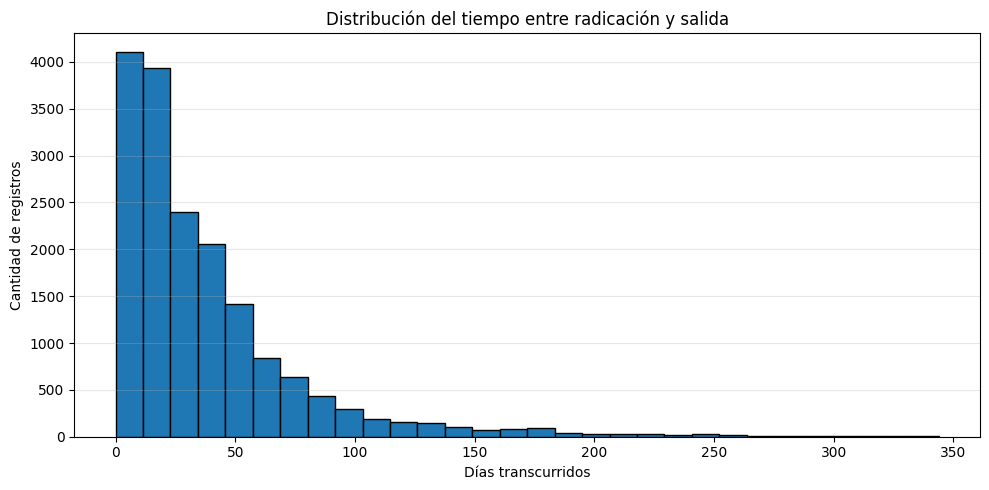

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_tiempos_validos["Dias_entre_radicacion_y_salida"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribución del tiempo entre radicación y salida")
plt.xlabel("Días transcurridos")
plt.ylabel("Cantidad de registros")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Q1: 12.16 días
Q3: 48.48 días
Rango intercuartílico: 36.32 días
Límite superior: 102.96 días
Posibles valores atípicos: 1092
Porcentaje de posibles atípicos: 6.35%


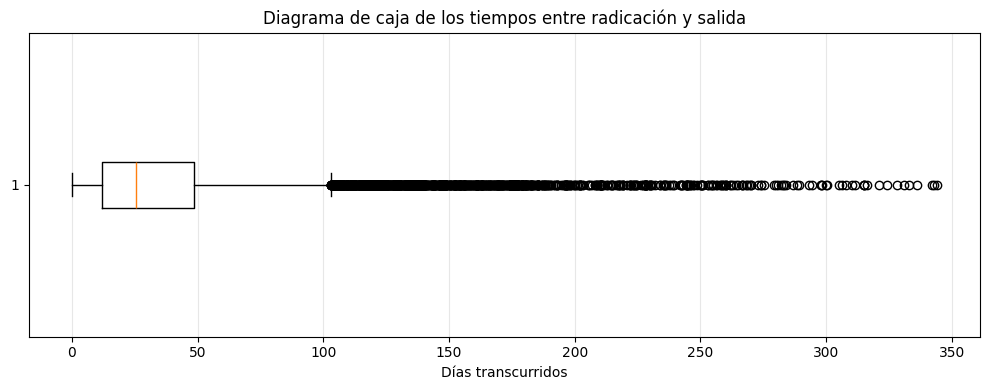

In [ ]:

import matplotlib.pyplot as plt

# Obtener cuartiles y calcular el rango intercuartílico
Q1 = df_tiempos_validos[
    "Dias_entre_radicacion_y_salida"
].quantile(0.25)

Q3 = df_tiempos_validos[
    "Dias_entre_radicacion_y_salida"
].quantile(0.75)

IQR = Q3 - Q1

# Límites estadísticos para identificar posibles valores atípicos
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar los registros que superan los límites
posibles_atipicos = df_tiempos_validos[
    (df_tiempos_validos["Dias_entre_radicacion_y_salida"] < limite_inferior)
    | (df_tiempos_validos["Dias_entre_radicacion_y_salida"] > limite_superior)
].copy()

print(f"Q1: {Q1:.2f} días")
print(f"Q3: {Q3:.2f} días")
print(f"Rango intercuartílico: {IQR:.2f} días")
print(f"Límite superior: {limite_superior:.2f} días")
print(f"Posibles valores atípicos: {len(posibles_atipicos)}")
print(
    f"Porcentaje de posibles atípicos: "
    f"{len(posibles_atipicos) / len(df_tiempos_validos) * 100:.2f}%"
)

# Diagrama de caja
plt.figure(figsize=(10, 4))
plt.boxplot(
    df_tiempos_validos["Dias_entre_radicacion_y_salida"],
    vert=False
)
plt.title("Diagrama de caja de los tiempos entre radicación y salida")
plt.xlabel("Días transcurridos")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Resumen estadístico de los tiempos por clase
resumen_tiempos_clase = (
    df_tiempos_validos
    .groupby("Clase")["Dias_entre_radicacion_y_salida"]
    .agg(
        Registros="count",
        Promedio="mean",
        Mediana="median",
        Desviacion_estandar="std",
        Minimo="min",
        Maximo="max"
    )
    .round(2)
)

display(resumen_tiempos_clase)


,Registros,Promedio,Mediana,Desviacion_estandar,Minimo,Maximo
Clase,,,,,,
OTRO,11380,43.47,31.91,45.54,0.00,343.99
PQRSD,5828,26.61,19.89,24.93,0.01,328.28


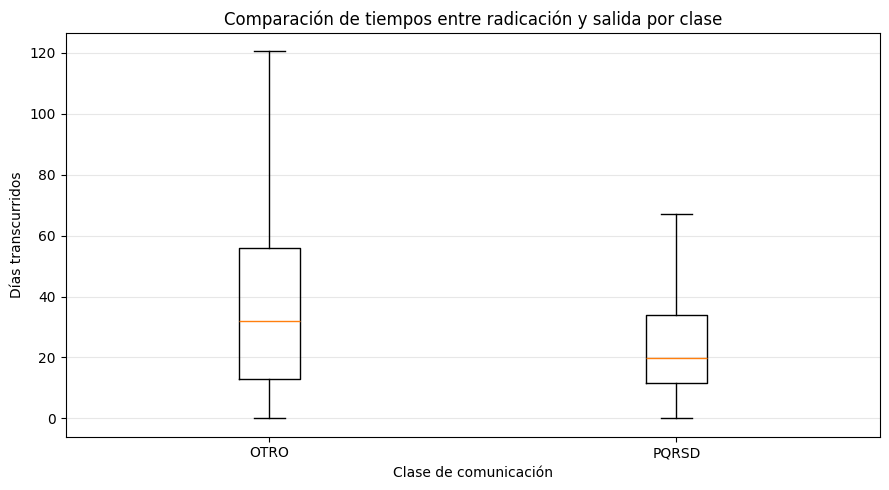

In [ ]:

import matplotlib.pyplot as plt

datos_otro = df_tiempos_validos.loc[
    df_tiempos_validos["Clase"] == "OTRO",
    "Dias_entre_radicacion_y_salida"
].dropna()

datos_pqrsd = df_tiempos_validos.loc[
    df_tiempos_validos["Clase"] == "PQRSD",
    "Dias_entre_radicacion_y_salida"
].dropna()

plt.figure(figsize=(9, 5))

plt.boxplot(
    [datos_otro, datos_pqrsd],
    tick_labels=["OTRO", "PQRSD"],
    showfliers=False
)

plt.title("Comparación de tiempos entre radicación y salida por clase")
plt.xlabel("Clase de comunicación")
plt.ylabel("Días transcurridos")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:

# Crear una copia para el análisis mensual
df_mensual = df_tiempos_validos.copy()

# Extraer el mes de la fecha de radicación
df_mensual["Mes"] = (
    df_mensual["Fecha radicación"].dt.month
)

# Calcular cantidad de registros y tiempos por mes
resumen_mensual = (
    df_mensual
    .groupby("Mes")
    .agg(
        Registros=("Dias_entre_radicacion_y_salida", "count"),
        Promedio_dias=("Dias_entre_radicacion_y_salida", "mean"),
        Mediana_dias=("Dias_entre_radicacion_y_salida", "median")
    )
    .round(2)
)

# Mostrar los meses en orden cronológico
nombres_meses = {
    1: "Enero", 2: "Febrero", 3: "Marzo",
    4: "Abril", 5: "Mayo", 6: "Junio",
    7: "Julio", 8: "Agosto", 9: "Septiembre",
    10: "Octubre", 11: "Noviembre", 12: "Diciembre"
}

resumen_mensual.index = [
    nombres_meses[mes] for mes in resumen_mensual.index
]

display(resumen_mensual)


,Registros,Promedio_dias,Mediana_dias
Enero,1024,44.25,30.93
Febrero,1219,43.04,23.38
Marzo,1467,48.72,34.20
Abril,1668,48.97,37.11
Mayo,1546,45.19,33.02
Junio,1276,44.76,35.26
Julio,1755,43.71,33.07
Agosto,1843,35.45,24.77
Septiembre,1916,31.40,26.16
Octubre,1523,25.16,20.37


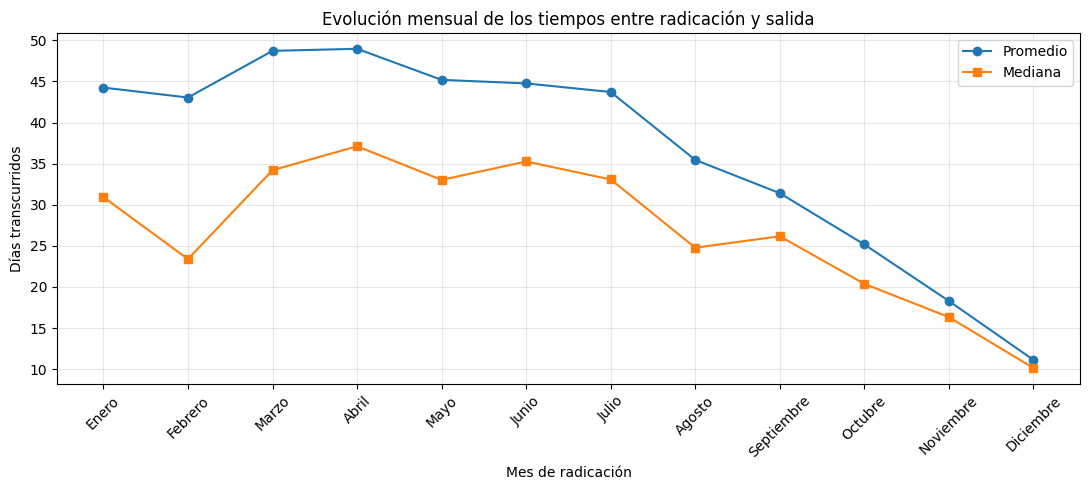

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.plot(
    resumen_mensual.index,
    resumen_mensual["Promedio_dias"],
    marker="o",
    label="Promedio"
)

plt.plot(
    resumen_mensual.index,
    resumen_mensual["Mediana_dias"],
    marker="s",
    label="Mediana"
)

plt.title("Evolución mensual de los tiempos entre radicación y salida")
plt.xlabel("Mes de radicación")
plt.ylabel("Días transcurridos")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Resumir los tiempos por mes y clase
df_mensual_clase = df_tiempos_validos.copy()

df_mensual_clase["Mes_numero"] = (
    df_mensual_clase["Fecha radicación"].dt.month
)

resumen_mensual_clase = (
    df_mensual_clase
    .groupby(["Mes_numero", "Clase"])
    .agg(
        Registros=("Dias_entre_radicacion_y_salida", "count"),
        Promedio_dias=("Dias_entre_radicacion_y_salida", "mean"),
        Mediana_dias=("Dias_entre_radicacion_y_salida", "median")
    )
    .round(2)
    .reset_index()
)

nombres_meses = {
    1: "Enero", 2: "Febrero", 3: "Marzo",
    4: "Abril", 5: "Mayo", 6: "Junio",
    7: "Julio", 8: "Agosto", 9: "Septiembre",
    10: "Octubre", 11: "Noviembre", 12: "Diciembre"
}

resumen_mensual_clase["Mes"] = (
    resumen_mensual_clase["Mes_numero"].map(nombres_meses)
)

display(
    resumen_mensual_clase[
        ["Mes", "Clase", "Registros", "Promedio_dias", "Mediana_dias"]
    ]
)


,Mes,Clase,Registros,Promedio_dias,Mediana_dias
0,Enero,OTRO,896,47.21,34.11
1,Enero,PQRSD,128,23.47,13.93
2,Febrero,OTRO,1005,48.09,30.88
3,Febrero,PQRSD,214,19.32,13.14
4,Marzo,OTRO,1244,52.96,38.18
5,Marzo,PQRSD,223,25.05,16.59
6,Abril,OTRO,1420,52.52,41.23
7,Abril,PQRSD,248,28.66,18.65
8,Mayo,OTRO,1299,46.84,34.40
9,Mayo,PQRSD,247,36.51,25.27


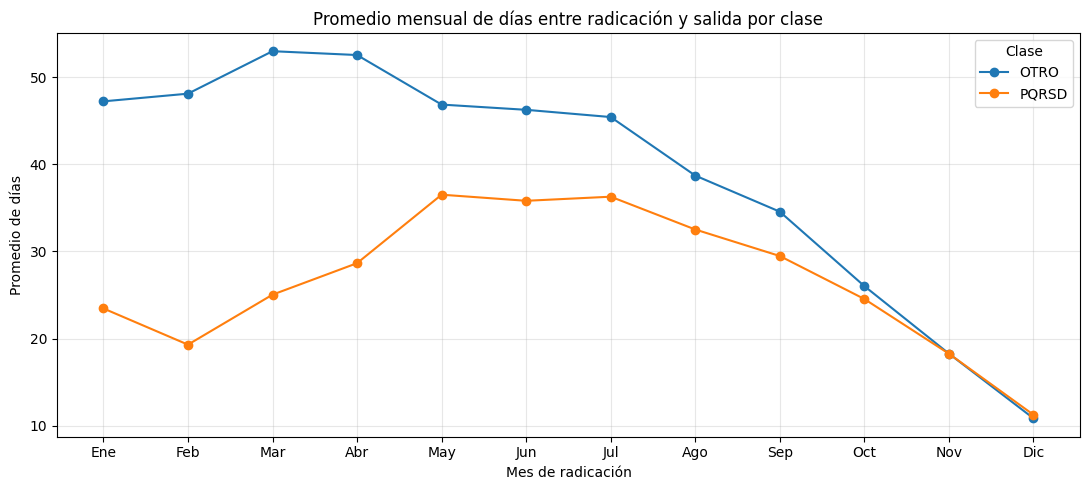

In [ ]:

import matplotlib.pyplot as plt

# Preparar los datos para graficar
tabla_grafica = resumen_mensual_clase.pivot(
    index="Mes_numero",
    columns="Clase",
    values="Promedio_dias"
).sort_index()

nombres_meses_cortos = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

plt.figure(figsize=(11, 5))

for clase in tabla_grafica.columns:
    plt.plot(
        range(1, 13),
        tabla_grafica[clase],
        marker="o",
        label=clase
    )

plt.title("Promedio mensual de días entre radicación y salida por clase")
plt.xlabel("Mes de radicación")
plt.ylabel("Promedio de días")
plt.xticks(range(1, 13), nombres_meses_cortos)
plt.legend(title="Clase")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Comparar dependencias con un volumen mínimo de 100 registros
resumen_dependencias = (
    df_vencimientos_validos
    .groupby("Dependencia asignada")
    .agg(
        Total=("Estado_vencimiento", "count"),
        Salidas_posteriores=(
            "Estado_vencimiento",
            lambda x: (x == "Salida posterior al vencimiento").sum()
        )
    )
)

resumen_dependencias["Porcentaje_posterior"] = (
    resumen_dependencias["Salidas_posteriores"]
    / resumen_dependencias["Total"] * 100
).round(2)

resumen_dependencias = resumen_dependencias[
    resumen_dependencias["Total"] >= 100
].sort_values(
    "Porcentaje_posterior",
    ascending=False
)

display(resumen_dependencias.head(10))


,Total,Salidas_posteriores,Porcentaje_posterior
Dependencia asignada,,,
GRUPO DE GESTIÓN INTEGRAL DE ENTIDADES LIQUIDADAS,2346,1647,70.20
DIRECCIÓN DE CADENAS AGRÍCOLAS Y FORESTALES,582,388,66.67
DIRECCIÓN DE CAPACIDADES PRODUCTIVAS Y GENERACIÓN DE INGRESOS,980,621,63.37
GRUPO DE CADENAS DE PRODUCTOS AGRÍCOLAS PERMANENTES Y HORTOFRUTÍCOLAS,247,154,62.35
GRUPO DE CADENAS DE PRODUCTOS AGRÍCOLAS TRANSITORIOS,499,303,60.72
GRUPO DE INNOVACIÓN Y DESARROLLO TECNOLÓGICO,302,176,58.28
DIRECCIÓN DE ORDENAMIENTO SOCIAL DE LA PROPIEDAD RURAL Y USO PRODUCTIVO DEL SUELO,1639,749,45.70
GRUPO DE GESTIÓN DOCUMENTAL Y BIBLIOTECA,2210,990,44.80
DESPACHO DEL VICEMINISTRO DE ASUNTOS AGROPECUARIOS,314,140,44.59


In [ ]:

import pandas as pd
from pathlib import Path

# Cargar la base final del proceso ETL
ruta = Path("/content/base_datos_auditada_etl_final.csv")

if not ruta.exists():
    print("No se encontró el archivo:", ruta)
else:
    base_final = pd.read_csv(
        ruta,
        parse_dates=[
            "Fecha radicación",
            "Fecha vencimiento",
            "Fecha Radicado salida"
        ]
    )

    print("DIMENSIONES DE LA BASE FINAL")
    print("Registros:", base_final.shape[0])
    print("Variables:", base_final.shape[1])

    print("\nTIPOS DE DATOS")
    display(base_final.dtypes.to_frame("Tipo de dato"))

    print("\nVALORES FALTANTES")
    faltantes = base_final.isna().sum().to_frame("Cantidad faltante")
    faltantes["Porcentaje (%)"] = (
        faltantes["Cantidad faltante"] / len(base_final) * 100
    ).round(2)

    display(faltantes[faltantes["Cantidad faltante"] > 0])

    print("\nVERIFICACIÓN DE ALERTAS TEMPORALES")
    if "Alerta_fecha_salida" in base_final.columns:
        print(
            "Registros con fecha de salida anterior a la radicación:",
            int(base_final["Alerta_fecha_salida"].sum())
        )
    else:
        print("La variable Alerta_fecha_salida no está en el archivo.")


DIMENSIONES DE LA BASE FINAL
Registros: 33842
Variables: 16

TIPOS DE DATOS


,Tipo de dato
No. de Radicado,object
Tipo comunicación,object
Clase,object
Tipo documento,object
Canal de recepción,object
Nombre del Peticionario / Remitente,object
Distribución,object
Dependencia asignada,object
Departamento,object
Municipio,object



VALORES FALTANTES


,Cantidad faltante,Porcentaje (%)
Nombre del Peticionario / Remitente,2998,8.86
Distribución,1466,4.33
No. Radicado de salida,16537,48.87
Fecha vencimiento,2678,7.91
Fecha Radicado salida,16537,48.87



VERIFICACIÓN DE ALERTAS TEMPORALES
Registros con fecha de salida anterior a la radicación: 97


In [ ]:

# Verificación de integridad de la base final

print("REGISTROS TOTALES:", len(base_final))

print(
    "Filas duplicadas completas:",
    base_final.duplicated().sum()
)

print(
    "Radicados de entrada faltantes:",
    base_final["No. de Radicado"].isna().sum()
)

print(
    "Radicados de entrada duplicados:",
    base_final["No. de Radicado"].duplicated().sum()
)

print(
    "Radicados de entrada únicos:",
    base_final["No. de Radicado"].nunique()
)


REGISTROS TOTALES: 33842
Filas duplicadas completas: 0
Radicados de entrada faltantes: 0
Radicados de entrada duplicados: 0
Radicados de entrada únicos: 33842


In [ ]:

# Resumen de las transformaciones realizadas

print("BASE ORIGINAL")
print("Registros:", 33842)
print("Variables originales:", 15)

print("\nBASE FINAL")
print("Registros:", base_final.shape[0])
print("Variables finales:", base_final.shape[1])

print("\nVARIABLES INCORPORADAS")
variables_nuevas = [
    col for col in base_final.columns
    if col not in [
        "No. de Radicado",
        "Tipo comunicación",
        "Clase",
        "Tipo documento",
        "Canal de recepción",
        "Nombre del Peticionario / Remitente",
        "Distribución",
        "Dependencia asignada",
        "Departamento",
        "Municipio",
        "No. Radicado de salida",
        "Fecha radicación",
        "Identificacion",
        "Fecha vencimiento",
        "Fecha Radicado salida"
    ]
]
print(variables_nuevas)

print("\nVARIABLES DE FECHA")
for columna in [
    "Fecha radicación",
    "Fecha vencimiento",
    "Fecha Radicado salida"
]:
    print(f"{columna}: {base_final[columna].dtype}")

print("\nALERTAS TEMPORALES")
print(base_final["Alerta_fecha_salida"].value_counts(dropna=False))


BASE ORIGINAL
Registros: 33842
Variables originales: 15

BASE FINAL
Registros: 33842
Variables finales: 16

VARIABLES INCORPORADAS
['Alerta_fecha_salida']

VARIABLES DE FECHA
Fecha radicación: datetime64[ns]
Fecha vencimiento: datetime64[ns]
Fecha Radicado salida: datetime64[ns]

ALERTAS TEMPORALES
Alerta_fecha_salida
False    33745
True        97
Name: count, dtype: int64


In [ ]:
# Diccionario de datos: estructura y valores faltantes

diccionario = pd.DataFrame({
    "Variable": base_final.columns,
    "Tipo de dato": base_final.dtypes.astype(str).values,
    "Valores faltantes": base_final.isna().sum().values,
    "Porcentaje faltante (%)": (
        base_final.isna().mean().values * 100
    ).round(2),
    "Valores únicos": base_final.nunique().values
})

display(diccionario)

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd

In [ ]:
diccionario = pd.DataFrame({
    "Variable": base_final.columns,
    "Tipo de dato": base_final.dtypes.astype(str).values,
    "Valores faltantes": base_final.isna().sum().values,
    "Porcentaje faltante (%)": (
        base_final.isna().mean().values * 100
    ).round(2),
    "Valores únicos": base_final.nunique().values
})

display(diccionario)

NameError: name 'base_final' is not defined

In [ ]:
import pandas as pd

base_final = pd.read_csv(
    "/content/base_datos_auditada_etl_final.csv",
    parse_dates=[
        "Fecha radicación",
        "Fecha vencimiento",
        "Fecha Radicado salida"
    ]
)

print("Base cargada correctamente")
print("Dimensiones:", base_final.shape)

FileNotFoundError: [Errno 2] No such file or directory: '/content/base_datos_auditada_etl_final.csv'

In [ ]:
import os

print("Archivos disponibles en /content:")
for archivo in os.listdir("/content"):
    print(archivo)

Archivos disponibles en /content:
.config
sample_data


In [ ]:
from google.colab import files

archivos = files.upload()

Saving base_datos_auditada_etl (1).csv to base_datos_auditada_etl (1).csv


In [ ]:
import pandas as pd

base_final = pd.read_csv(
    "/content/base_datos_auditada_etl_final.csv",
    parse_dates=[
        "Fecha radicación",
        "Fecha vencimiento",
        "Fecha Radicado salida"
    ]
)

print("Dimensiones:", base_final.shape)
display(base_final.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/base_datos_auditada_etl_final.csv'

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'base_datos_auditada_etl (1).csv', 'sample_data']


In [ ]:
import pandas as pd

base_final = pd.read_csv(
    "/content/base_datos_auditada_etl (1).csv",
    parse_dates=[
        "Fecha radicación",
        "Fecha vencimiento",
        "Fecha Radicado salida"
    ]
)

print("Base cargada correctamente")
print("Dimensiones:", base_final.shape)

Base cargada correctamente
Dimensiones: (33842, 16)


In [ ]:
diccionario = pd.DataFrame({
    "Variable": base_final.columns,
    "Tipo de dato": base_final.dtypes.astype(str).values,
    "Valores faltantes": base_final.isna().sum().values,
    "Porcentaje faltante (%)": (
        base_final.isna().mean().values * 100
    ).round(2),
    "Valores únicos": base_final.nunique().values
})

display(diccionario)

,Variable,Tipo de dato,Valores faltantes,Porcentaje faltante (%),Valores únicos
0,No. de Radicado,object,0,0.00,33842
1,Tipo comunicación,object,0,0.00,1
2,Clase,object,0,0.00,2
3,Tipo documento,object,0,0.00,34
4,Canal de recepción,object,0,0.00,4
5,Nombre del Peticionario / Remitente,object,2998,8.86,11192
6,Distribución,object,1466,4.33,2
7,Dependencia asignada,object,0,0.00,59
8,Departamento,object,0,0.00,33
9,Municipio,object,0,0.00,482


In [ ]:
print("Valores únicos de Identificacion:")
print(base_final["Identificacion"].value_counts(dropna=False))

print("\nPrimeros registros:")
display(base_final[["Identificacion", "No. de Radicado"]].head(10))

Valores únicos de Identificacion:
Identificacion
1111    33842
Name: count, dtype: int64

Primeros registros:


,Identificacion,No. de Radicado
0,1111,2025-313-000001-2
1,1111,2025-313-000002-2
2,1111,2025-313-000003-2
3,1111,2025-313-000004-2
4,1111,2025-313-000005-2
5,1111,2025-313-000006-2
6,1111,2025-313-000007-2
7,1111,2025-313-000008-2
8,1111,2025-313-000009-2
9,1111,2025-313-000010-2


In [ ]:
for columna in base_final.columns:
    cantidad = base_final[columna].nunique()

    if cantidad == 1:
        print(
            f"{columna}: "
            f"{base_final[columna].dropna().unique()[0]}"
        )

Tipo comunicación: Comunicación Oficial Externa Recibida
Identificacion: 1111


In [ ]:
variables_categoricas = [
    "Tipo comunicación",
    "Clase",
    "Tipo documento",
    "Canal de recepción",
    "Distribución",
    "Dependencia asignada",
    "Departamento",
    "Municipio"
]

for variable in variables_categoricas:
    print(f"\n{'='*60}")
    print(f"VARIABLE: {variable}")
    print(f"Valores diferentes: {base_final[variable].nunique()}")
    print(base_final[variable].value_counts(dropna=False).to_string())


VARIABLE: Tipo comunicación
Valores diferentes: 1
Tipo comunicación
Comunicación Oficial Externa Recibida    33842

VARIABLE: Clase
Valores diferentes: 2
Clase
OTRO     26386
PQRSD     7456

VARIABLE: Tipo documento
Valores diferentes: 34
Tipo documento
Oficio                                                                                16817
Otros                                                                                  4325
Tutela                                                                                 2970
Derechos de Petición (Interés General - Particular - Escrito o Verbal)                 2571
Solicitud de Información y/o Copia de documentos                                       2292
Consultas y Conceptos                                                                   905
Derechos de Petición entre Entidades                                                    766
Comunicacion oficial general                                                            701
Convocato

In [ ]:
variables_restantes = [
    "No. de Radicado",
    "Nombre del Peticionario / Remitente",
    "No. Radicado de salida",
    "Fecha radicación",
    "Identificacion",
    "Fecha vencimiento",
    "Fecha Radicado salida",
    "Alerta_fecha_salida"
]

for variable in variables_restantes:
    print(f"\n{'='*55}")
    print(f"VARIABLE: {variable}")
    print("Tipo:", base_final[variable].dtype)
    print("Valores únicos:", base_final[variable].nunique())
    print("Valores faltantes:", base_final[variable].isna().sum())
    print("Ejemplos:")
    print(base_final[variable].dropna().head(5).to_list())


VARIABLE: No. de Radicado
Tipo: object
Valores únicos: 33842
Valores faltantes: 0
Ejemplos:
['2025-313-000001-2', '2025-313-000002-2', '2025-313-000003-2', '2025-313-000004-2', '2025-313-000005-2']

VARIABLE: Nombre del Peticionario / Remitente
Tipo: object
Valores únicos: 11192
Valores faltantes: 2998
Ejemplos:
['PRESIDENCIA DE LA REPÚBLICA', 'PRESIDENCIA DE LA REPUBLICA', 'PRESIDENCIA DE LA REPÚBLICA', 'COLPÈNSION', 'COLPENSIONES']

VARIABLE: No. Radicado de salida
Tipo: object
Valores únicos: 16884
Valores faltantes: 16537
Ejemplos:
['2025-420-000713-1', '2025-311-000115-1', '2025-521-000903-1', '2025-540-000056-1', '2025-522-000932-1']

VARIABLE: Fecha radicación
Tipo: datetime64[ns]
Valores únicos: 33805
Valores faltantes: 0
Ejemplos:
[Timestamp('2025-01-02 08:26:31'), Timestamp('2025-01-02 08:37:39'), Timestamp('2025-01-02 08:37:45'), Timestamp('2025-01-02 08:37:52'), Timestamp('2025-01-02 08:37:58')]

VARIABLE: Identificacion
Tipo: int64
Valores únicos: 1
Valores faltantes: 0
E

In [ ]:
variables_fecha = [
    "Fecha radicación",
    "Fecha vencimiento",
    "Fecha Radicado salida"
]

for variable in variables_fecha:
    print(f"\nVARIABLE: {variable}")
    print("Fecha mínima:", base_final[variable].min())
    print("Fecha máxima:", base_final[variable].max())
    print("Valores faltantes:", base_final[variable].isna().sum())


VARIABLE: Fecha radicación
Fecha mínima: 2025-01-02 08:26:31
Fecha máxima: 2025-12-31 17:53:58
Valores faltantes: 0

VARIABLE: Fecha vencimiento
Fecha mínima: 2025-01-02 13:04:46
Fecha máxima: 2026-02-16 23:59:00
Valores faltantes: 2678

VARIABLE: Fecha Radicado salida
Fecha mínima: 2024-10-31 18:17:00
Fecha máxima: 2026-01-05 14:49:05
Valores faltantes: 16537


In [ ]:
!pip freeze > requirements.txt